In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
df=pd.read_csv('/content/drive/MyDrive/Ames_Housing_Data.csv')

In [ ]:
df.head()

,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


In [ ]:
def percent_na(df):
  return df.isna().sum()/len(df)*100


In [ ]:
100/len(df)

0.034129692832764506

In [ ]:
nas=percent_na(df)
nas=nas[nas!=0].sort_values()
nas


,0
Lot Frontage,16.672408
Fireplace Qu,48.570444
Mas Vnr Type,60.213572


In [ ]:
df['Misc Feature']=df['Misc Feature'].fillna('None')

In [ ]:
df=df.drop('Pool QC',axis=1)
df=df.drop('PID',axis=1)

In [ ]:
df=df.drop('Fence',axis=1)

In [ ]:
df=df.drop(df[df['Bsmt Unf SF'].isna()].index)

(0.0, 1.0)

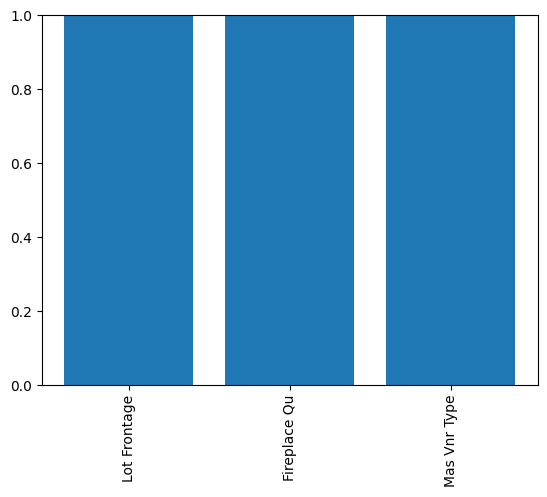

In [ ]:
plt.bar(x=nas.index,height=nas)
plt.xticks(rotation=90)
plt.ylim((0,1))

In [ ]:
df=df.drop(df[df['Bsmt Full Bath'].isna()].index)

In [ ]:
df=df.drop(df[df['Garage Area'].isna()].index)

In [ ]:
df=df.drop(df[df['Electrical'].isna()].index)

In [ ]:
df=df.drop(df[df['Mas Vnr Area'].isna()].index)

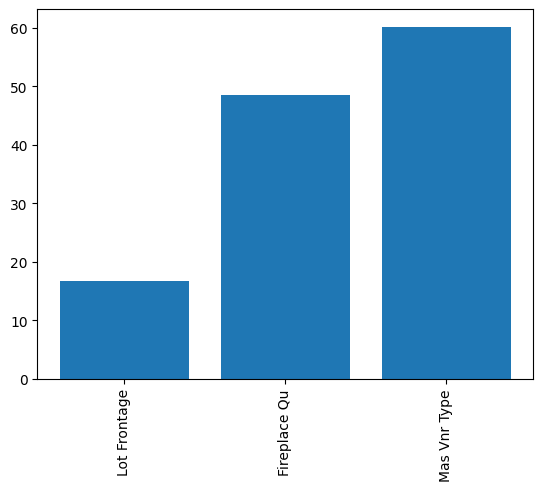

In [ ]:
plt.bar(x=nas.index,height=nas)
plt.xticks(rotation=90)
# plt.ylim((0,1))
plt.show()

In [ ]:
df['Alley']=df['Alley'].fillna('No alley acces')

In [ ]:
df['Garage Type']=df['Garage Type'].fillna('No Garage')

In [ ]:
df=df.drop('Garage Yr Blt',axis=1)

In [ ]:
df['Garage Qual']=df['Garage Qual'].fillna('No garage')

In [ ]:
df=df.drop('Garage Cond',axis=1)

In [ ]:
df=df.drop('Garage Finish',axis=1)

In [ ]:
df=df.drop('Bsmt Cond',axis=1)

In [ ]:
df['BsmtFin Type 1']=df['BsmtFin Type 1'].fillna('NO BASEMENT')

In [ ]:
df['BsmtFin Type 2']=df['BsmtFin Type 2'].fillna('NO BASEMENT')

In [ ]:
df['Bsmt Qual']=df['Bsmt Qual'].fillna('NO BASEMENT')

In [ ]:
df['Bsmt Exposure']=df['Bsmt Exposure'].fillna('NO BASEMENT')

In [ ]:
df=df.drop('Lot Frontage',axis=1)

In [ ]:
df=df.drop('Fireplace Qu',axis=1)

In [ ]:
df=df.drop('Mas Vnr Type',axis=1)

In [ ]:
df.info(

)

<class 'pandas.core.frame.DataFrame'>
Index: 2903 entries, 0 to 2929
Data columns (total 71 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   MS SubClass      2903 non-null   int64  
 1   MS Zoning        2903 non-null   object 
 2   Lot Area         2903 non-null   int64  
 3   Street           2903 non-null   object 
 4   Alley            2903 non-null   object 
 5   Lot Shape        2903 non-null   object 
 6   Land Contour     2903 non-null   object 
 7   Utilities        2903 non-null   object 
 8   Lot Config       2903 non-null   object 
 9   Land Slope       2903 non-null   object 
 10  Neighborhood     2903 non-null   object 
 11  Condition 1      2903 non-null   object 
 12  Condition 2      2903 non-null   object 
 13  Bldg Type        2903 non-null   object 
 14  House Style      2903 non-null   object 
 15  Overall Qual     2903 non-null   int64  
 16  Overall Cond     2903 non-null   int64  
 17  Year Built       29

In [ ]:
abs(df.corr(numeric_only=True)['SalePrice']).sort_values()

,SalePrice
BsmtFin SF 2,0.008022
Misc Val,0.015326
Yr Sold,0.027831
Mo Sold,0.030556
3Ssn Porch,0.032927
Bsmt Half Bath,0.034763
Low Qual Fin SF,0.037359
Pool Area,0.069103
MS SubClass,0.083610
Overall Cond,0.099796


In [ ]:
df=df.drop(['BsmtFin SF 2'],axis=1)

In [ ]:
df_final=pd.get_dummies(df)

In [ ]:
X=df_final.drop('SalePrice',axis=1)

In [ ]:
y=df_final['SalePrice']

In [ ]:
from sklearn.model_selection import cross_val_score,train_test_split

X_train, X_test,y_train, y_test=train_test_split(X,y,test_size=0.2,random_state=42)


In [ ]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
scaler.fit(X_train)
X_train=scaler.transform(X_train)
X_test=scaler.transform(X_test)

In [ ]:
from sklearn.linear_model import Ridge
model=Ridge(alpha=1)

In [ ]:
cross_val_score(model,X_train,y_train,scoring='neg_mean_squared_error',cv=5)

array([-5.05695992e+08, -7.96343407e+08, -8.04665576e+08, -4.41444562e+08,
       -1.99612646e+09])

In [ ]:
model.fit(X_train,y_train)

Ridge(alpha=1)

In [ ]:
model.score(X_train,y_train)

0.9373329741934089

In [ ]:
model.score(X_test,y_test)

0.892657343766616

In [ ]:
y_pred=model.predict(X_test)

In [ ]:
from sklearn.metrics import mean_absolute_error,mean_squared_error
RMSE=np.sqrt(mean_squared_error(y_test,y_pred))
MAe=mean_absolute_error(y_test,y_pred)

In [ ]:
RMSE,MAe

(np.float64(26872.958852476575), 16350.923232976314)